# Multi-Family Biophysical Featurization: Beyond Pairwise Contacts

[![Open in JupyterLab](https://img.shields.io/badge/Launch-JupyterLab-orange.svg)](https://jupyter.org)
[![Python 3.10+](https://img.shields.io/badge/python-3.10+-blue.svg)](https://www.python.org/)
[![Documentation](https://img.shields.io/badge/docs-MolScope-blue.svg)](https://github.com/N-S8990/molscope)

Most molecular dynamics analysis toolkits restrict trajectory featurization to pairwise contact maps or Cartesian coordinates. While pairwise distances can track large domain hinge motions, they frequently miss subtle local structural reorganizations—such as $\alpha \to 3_{10}$ helical transitions, buried hydrophobic core rotamer flips, solvent-accessible cavity openings, and electrostatic latching.

MolScope provides an extensible library of **17+ biophysical feature plugins**, allowing researchers to construct comprehensive multi-family panels:
1. **Cα Distances & Interaction Graphs**: Bounded inter-residue distance metrics and binary contact networks.
2. **Secondary Structure Tracking via DSSP**: Fractions of $\alpha$-helix, $\beta$-sheet, and coil/turn elements.
3. **Circular Sidechain & Backbone Torsions**: Continuous $[\sin(\theta), \cos(\theta)]$ trigonometric representations avoiding boundary wrap discontinuities.
4. **Solvent Accessible Surface Area (SASA)**: All-atom and residue-level surface hydration using FreeSASA.
5. **Electrostatic Salt Bridges**: Specific basic–acidic ionic pair tracking ($d \le 4.0$ Å).
6. **Aromatic $\pi$-$\pi$ Stacking Geometries**: Centroid distances and planar tilt angles.

In this notebook, we verify MolScope's `PLUGIN_REGISTRY`, configure a multi-family featurization panel on the Villin Headpiece (HP35), extract features, and evaluate cross-family correlations and orthogonal biophysical signals.

## 1. Feature Family Overview & Plugin Registry Verification

MolScope discovers and registers all feature plugins through `PLUGIN_REGISTRY` in `molscope.features.plugins`.
Each plugin declares its unique identifier, required system capabilities (e.g., `'coordinates'`, `'protein'`, `'bonds'`), and computation scope.

In [1]:
import pandas as pd
from molscope.features.plugins import PLUGIN_REGISTRY

# Inspect all registered feature plugins in MolScope
plugin_records = []
for plugin_id, plugin in sorted(PLUGIN_REGISTRY.items()):
    doc = (plugin.__doc__ or "").strip().split("\n")[0]
    caps = sorted(getattr(plugin, "required_capabilities", []))
    family = plugin_id.split(".")[0]
    plugin_records.append({
        "Plugin ID": plugin_id,
        "Family": family,
        "Required Capabilities": ", ".join(caps) if caps else "None",
        "Scientific Description": doc,
    })

df_plugins = pd.DataFrame(plugin_records)
print(f"Total Registered Feature Plugins in MolScope: {len(df_plugins)}")
df_plugins

Total Registered Feature Plugins in MolScope: 17


,Plugin ID,Family,Required Capabilities,Scientific Description
0,coordinates.selected_atoms,coordinates,coordinates,Export a bounded named atom selection as its s...
1,electrostatics.molecular_dipole,electrostatics,"coordinates, partial_charges",Dipole magnitude for a neutral selected molecu...
2,ligand.plif,ligand,"coordinates, protein, small_molecule_or_polymer",Protein-Ligand Interaction Fingerprints (PLIF)...
3,networks.protein_contact_network,networks,"coordinates, protein",Dynamic residue-contact networks with explicit...
4,nucleic_acid.base_proximities,nucleic_acid,"coordinates, nucleic_acid",Nucleic-acid base-center proximity descriptors...
5,protein.aromatic_stacking,protein,"coordinates, protein",PHE/TYR ring-plane stacking geometry with cons...
6,protein.backbone_torsions,protein,"bonds, protein_backbone","Protein-only phi, psi, and omega torsions with..."
7,protein.ca_distances_contacts,protein,"coordinates, protein",Bounded Cα pair distances and a conventional r...
8,protein.hydrogen_bonds,protein,"bonds, coordinates, hydrogens, protein",Protein hydrogen bonds with explicit donor-H b...
9,protein.hydrophobic_contacts,protein,"coordinates, protein",Nonlocal contacts between declared hydrophobic...


## 2. Mathematical Formulations and Biophysical Representations

| Feature Family | Plugin ID | Mathematical Formulation | Biophysical Role |
| :--- | :--- | :--- | :--- |
| **Cα Distances & Contacts** | `protein.ca_distances_contacts` | $d_{ij} = \|\mathbf{r}_i - \mathbf{r}_j\|$, $\Theta(d_{\text{cut}} - d_{ij})$ | Domain motions, tertiary fold stability |
| **Secondary Structure** | `protein.secondary_structure_dssp` | $f_\alpha = \frac{N_\alpha}{N_{\text{res}}}$, $f_\beta = \frac{N_\beta}{N_{\text{res}}}$, $f_c = \frac{N_c}{N_{\text{res}}}$ | Helix-coil transitions, unfolding |
| **Circular Sidechain Rotamers** | `protein.sidechain_torsions` | $[\sin(\chi_1), \cos(\chi_1), \sin(\chi_2), \cos(\chi_2)]$ | Hydrophobic core packing, rotamer flips |
| **Circular Backbone Torsions** | `protein.backbone_torsions` | $[\sin(\phi), \cos(\phi), \sin(\psi), \cos(\psi)]$ | Ramachandran regional shifts |
| **Solvent Exposure (SASA)** | `structural.sasa` | Surface area ($Å^2$) via rolling probe sphere (1.4 Å) | Hydrophobic burial, cavity opening |
| **Salt Bridges** | `protein.salt_bridges` | $d(\text{Arg/Lys}^+, \text{Asp/Glu}^-) \le 4.0$ Å | Electrostatic latching, pH sensitivity |
| **Aromatic Stacking** | `protein.aromatic_stacking` | Centroid distance $d \le 5.5$ Å, normal angle $\theta$ | $\pi$-system stabilization |

> **Why Circular $[\sin(\theta), \cos(\theta)]$ Torsions?**
> Standard dihedral angles range in $[-\pi, +\pi]$ or $[0^\circ, 360^\circ]$. Direct numerical featurization creates an artificial numerical jump discontinuity when a torsion fluctuates across $+180^\circ$ and $-180^\circ$. By decomposing $\theta$ into $[\sin(\theta), \cos(\theta)]$, the feature space becomes topologically continuous ($S^1 \to \mathbb{R}^2$), allowing distance-based and linear ML algorithms (TICA, PCA, Ridge/Lasso) to operate smoothly without angle-wrap artifacts.

## 3. Dataset Ingestion and System Setup

We locate the 64-residue HP35 Villin Headpiece folding trajectory (`data/2RJY`), with automatic fallback to `tests/fixtures/1A22.pdb` if the full simulation trajectory is absent.

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from molscope.api import Study

# Locate 2RJY dataset with robust fallback
data_candidates = [
    Path("data/2RJY"),
    Path("../data/2RJY"),
]
data_dir = next((p for p in data_candidates if (p / "protein.pdb").is_file() and (p / "simulation_run1.xtc").is_file()), None)

if data_dir is not None:
    topology_file = data_dir / "protein.pdb"
    trajectory_file = data_dir / "simulation_run1.xtc"
    sidechain_resids = [47, 51, 58]  # Canonical hydrophobic core Phe residues
    ca_selection = "protein and name CA"
    is_fallback = False
    print(f"Dataset located: {data_dir} (Full 2RJY Folding Trajectory)")
else:
    fallback_pdb = Path("tests/fixtures/1A22.pdb")
    if not fallback_pdb.is_file():
        fallback_pdb = Path("../tests/fixtures/1A22.pdb")
    topology_file = fallback_pdb
    trajectory_file = fallback_pdb
    sidechain_resids = [4, 6, 8, 10]
    ca_selection = "protein and resid 1-35 and name CA"
    is_fallback = True
    print(f"Trajectory fallback active: {topology_file}")

print(f"Topology:   {topology_file}")
print(f"Trajectory: {trajectory_file}")

Dataset located: data/2RJY (Full 2RJY Folding Trajectory)
Topology:   data/2RJY/protein.pdb
Trajectory: data/2RJY/simulation_run1.xtc


## 4. Configuring and Extracting Multi-Family Panels

We initialize a MolScope `Study` workspace and configure a comprehensive multi-family feature extraction panel comprising:
- **`protein.ca_distances_contacts`**: Bounded pairwise distances ($\le 8.0$ Å cutoff).
- **`protein.secondary_structure_dssp`**: Global secondary structure fractions via native DSSP.
- **`protein.sidechain_torsions`**: Continuous circular rotamers ($\chi_1, \chi_2$) for core aromatic residues.
- **`protein.salt_bridges`**: Specific ionic network pairs.
- **`structural.sasa`**: All-atom and residue-level Solvent Accessible Surface Area via FreeSASA.
- **`protein.aromatic_stacking`**: Aromatic ring plane centroid distances and tilt angles.

In [3]:
out_dir = Path("results/notebook_features")
out_dir.mkdir(parents=True, exist_ok=True)

study = Study(
    project_id="multi_family_showcase",
    out_dir=out_dir,
)

# Register the system
study.add_system(
    system_id="villin_headpiece" if not is_fallback else "1a22_demo",
    topology=topology_file,
    trajectories=[trajectory_file],
    condition_label="folding_trajectory" if not is_fallback else "reference_conformation",
)

# Configure periodic boundary condition imaging
study.configure_imaging(unwrap=not is_fallback, center_selection="protein")

# Configure multi-family feature panel
study.configure_features(
    plugins=[
        "protein.ca_distances_contacts",
        "protein.secondary_structure_dssp",
        "protein.sidechain_torsions",
        "protein.salt_bridges",
        "structural.sasa",
        "protein.aromatic_stacking",
    ],
    plugin_parameters={
        "protein.ca_distances_contacts": {
            "selection": ca_selection,
            "contact_cutoff_angstrom": 8.0,
            "max_pairs": 3000,
        },
        "protein.secondary_structure_dssp": {
            "per_residue": False,
        },
        "protein.sidechain_torsions": {
            "residue_ids": sidechain_resids,
        },
    },
    generic_parameters={
        "frame_stride": 50 if not is_fallback else 1,
        "max_frames": 200,
    },
)

print("Extracting multi-family biophysical features...")
study.run(extract_only=True)

features = study.get_features()
manifest = study.get_manifest()

print(f"Successfully extracted {features.shape[1]} features across {features.shape[0]} trajectory frames.")
features.iloc[:5, :8]

Extracting multi-family biophysical features...


Successfully extracted 3869 features across 200 trajectory frames.


,GEOM_global_radius_gyration,GEOM_global_asphericity,DYN_kabsch_rmsd_to_first_frame,CA_DISTANCE_angstrom__SYSTEM__LEU_13__SYSTEM__PHE_16,CA_CONTACT__SYSTEM__LEU_13__SYSTEM__PHE_16,CA_DISTANCE_angstrom__SYSTEM__LEU_13__SYSTEM__PRO_17,CA_CONTACT__SYSTEM__LEU_13__SYSTEM__PRO_17,CA_DISTANCE_angstrom__SYSTEM__LEU_13__SYSTEM__LEU_18
0,11.581391,0.326638,0.000000,10.069449,0.0,13.457719,0.0,15.639076
1,11.715962,0.348728,1.975827,9.723115,0.0,13.329742,0.0,15.023409
2,11.618797,0.349835,1.492933,9.758243,0.0,13.309431,0.0,14.920358
3,11.607625,0.349245,1.840556,10.373373,0.0,13.852457,0.0,15.760952
4,11.699837,0.322956,1.977214,9.894986,0.0,13.455800,0.0,15.000364


## 5. Feature Decomposition by Biophysical Family

Let us decompose the extracted feature matrix by biophysical family and inspect their dimensions and relative representation.

,Feature Family,Feature Count,Percentage (%)
0,Cα Pair Distances,1891,48.88
1,Cα Binary Contacts,1891,48.88
2,Solvent Accessible Area (SASA),65,1.68
3,Circular Sidechain Rotamers,12,0.31
4,Global Shape & RMSD,3,0.08
5,DSSP Secondary Structure,3,0.08
6,Electrostatic Salt Bridges,2,0.05
7,Aromatic π-Stacking,2,0.05


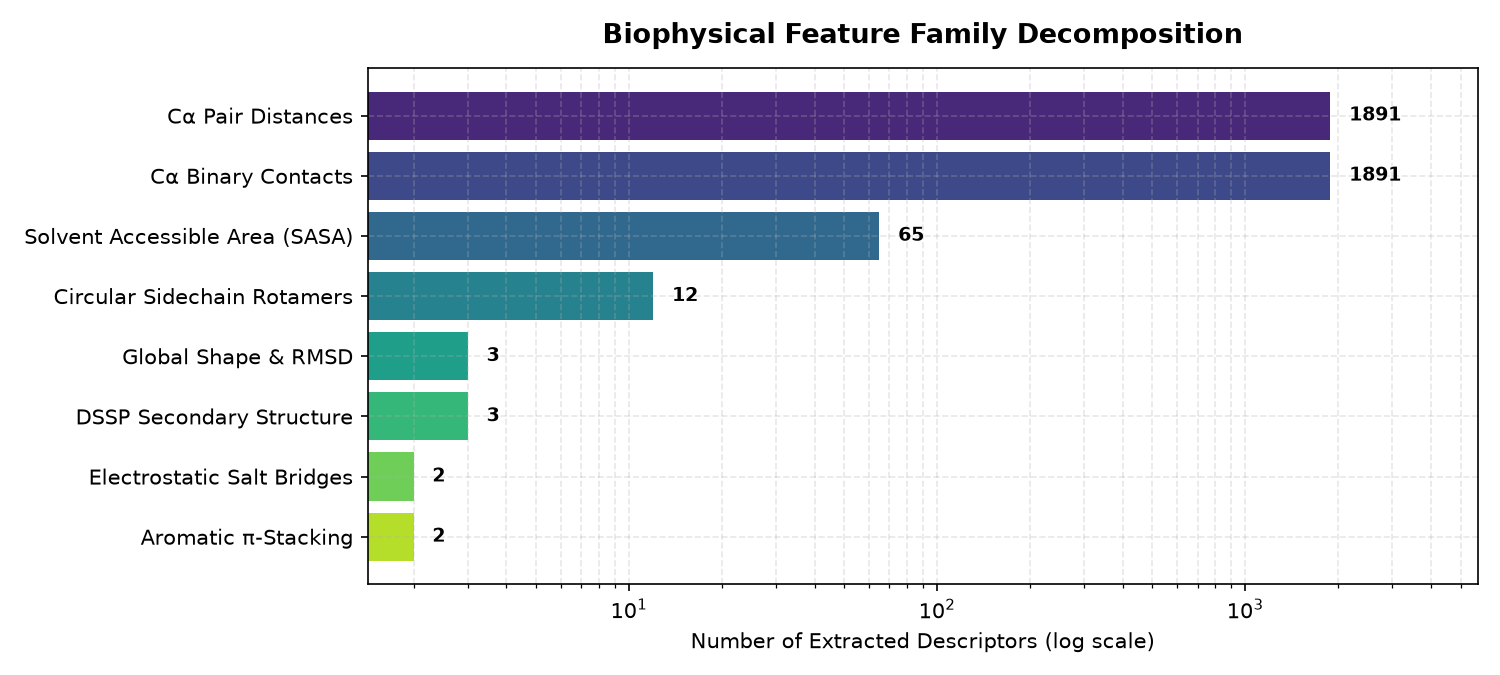

In [4]:
# Classify features by biophysical family
def classify_family(col: str) -> str:
    if col.startswith("CA_DISTANCE_"):
        return "Cα Pair Distances"
    elif col.startswith("CA_CONTACT_"):
        return "Cα Binary Contacts"
    elif col.startswith("DSSP_"):
        return "DSSP Secondary Structure"
    elif col.startswith("SIDECHAIN_"):
        return "Circular Sidechain Rotamers"
    elif col.startswith("SASA_"):
        return "Solvent Accessible Area (SASA)"
    elif col.startswith("SALT_BRIDGE_"):
        return "Electrostatic Salt Bridges"
    elif col.startswith("AROMATIC_"):
        return "Aromatic π-Stacking"
    elif col.startswith("GEOM_") or col.startswith("DYN_"):
        return "Global Shape & RMSD"
    return "Other Invariants"

family_series = pd.Series([classify_family(c) for c in features.columns], index=features.columns)
family_counts = family_series.value_counts()

df_family_summary = pd.DataFrame({
    "Feature Family": family_counts.index,
    "Feature Count": family_counts.values,
    "Percentage (%)": (family_counts.values / len(features.columns) * 100).round(2),
})

# Display summary table
display(df_family_summary)

# Bar chart of feature families
plt.figure(figsize=(10, 4.5))
palette = sns.color_palette("viridis", len(family_counts))
bars = plt.barh(df_family_summary["Feature Family"], df_family_summary["Feature Count"], color=palette)
plt.title("Biophysical Feature Family Decomposition", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Number of Extracted Descriptors (log scale)")
plt.xscale("log")
plt.grid(True, which="both", linestyle="--", alpha=0.3)
for bar in bars:
    w = bar.get_width()
    plt.text(w * 1.15, bar.get_y() + bar.get_height() / 2, f"{int(w)}", va="center", fontsize=9, fontweight="bold")
plt.xlim(right=family_counts.max() * 3)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Trajectory Dynamics: Biophysical Feature Time-Series Panels

Because features are extracted across the trajectory, we can visualize complementary biophysical processes happening in synchrony:
1. **Secondary Structure Evolution**: Transitions between unfolded coil/turn and folded $\alpha$-helix.
2. **Hydration & Compaction**: Expansion/compaction measured simultaneously by Radius of Gyration ($R_g$) and Total SASA ($Å^2$).
3. **Circular Rotamer Basins**: Free energy rotamer wells explored by Phe47 in continuous circular coordinates $[\sin(\chi_1), \cos(\chi_1)]$.
4. **Non-Covalent Network Dynamics**: Salt bridge and aromatic $\pi$-$\pi$ stacking formations stabilizing key intermediates.

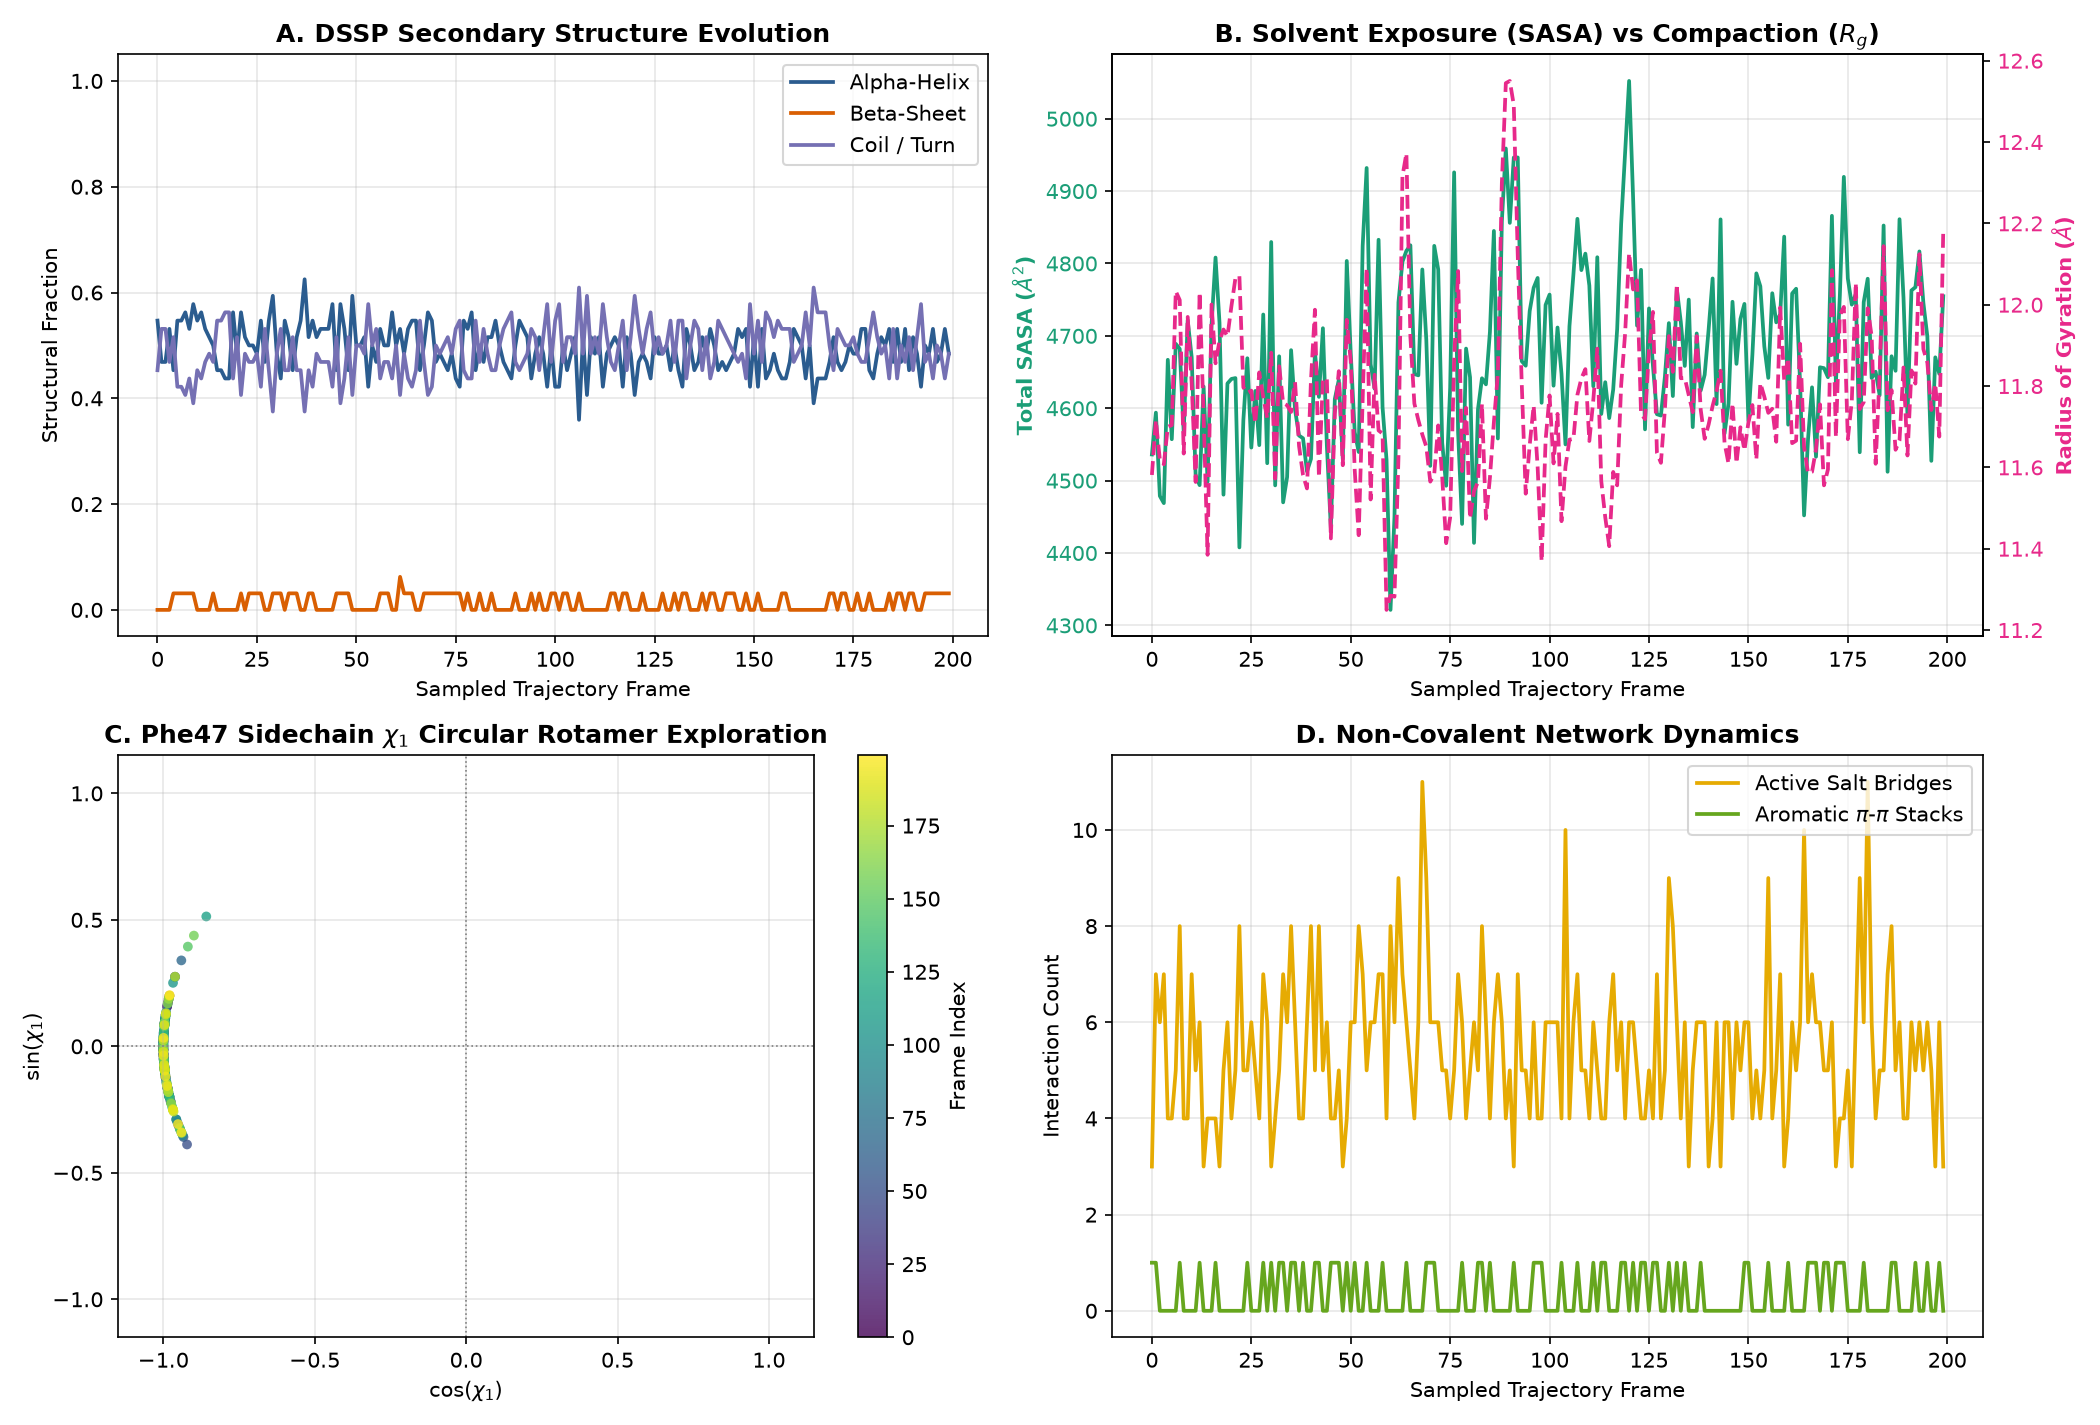

In [5]:
frames = np.arange(len(features))
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# Panel 1: DSSP Secondary Structure Trajectory
ax1 = axes[0, 0]
if "DSSP_helix_fraction" in features.columns:
    ax1.plot(frames, features["DSSP_helix_fraction"], label="Alpha-Helix", color="#2b5c8f", lw=1.8)
if "DSSP_sheet_fraction" in features.columns:
    ax1.plot(frames, features["DSSP_sheet_fraction"], label="Beta-Sheet", color="#d95f02", lw=1.8)
if "DSSP_coil_fraction" in features.columns:
    ax1.plot(frames, features["DSSP_coil_fraction"], label="Coil / Turn", color="#7570b3", lw=1.8)
ax1.set_title("A. DSSP Secondary Structure Evolution", fontsize=12, fontweight="bold")
ax1.set_xlabel("Sampled Trajectory Frame")
ax1.set_ylabel("Structural Fraction")
ax1.set_ylim(-0.05, 1.05)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper right", frameon=True)

# Panel 2: Total Solvent Accessible Surface Area vs Radius of Gyration
ax2 = axes[0, 1]
color_sasa = "#1b9e77"
color_rg = "#e7298a"
if "SASA_total" in features.columns:
    ax2.plot(frames, features["SASA_total"], color=color_sasa, lw=1.8, label="Total SASA")
    ax2.set_ylabel(r"Total SASA ($\AA^2$)", color=color_sasa, fontweight="bold")
    ax2.tick_params(axis="y", labelcolor=color_sasa)
ax2.set_xlabel("Sampled Trajectory Frame")
ax2.grid(True, alpha=0.3)
ax2.set_title(r"B. Solvent Exposure (SASA) vs Compaction ($R_g$)", fontsize=12, fontweight="bold")

if "GEOM_global_radius_gyration" in features.columns:
    ax2_twin = ax2.twinx()
    ax2_twin.plot(frames, features["GEOM_global_radius_gyration"], color=color_rg, lw=1.8, linestyle="--", label="Rg")
    ax2_twin.set_ylabel(r"Radius of Gyration ($\AA$)", color=color_rg, fontweight="bold")
    ax2_twin.tick_params(axis="y", labelcolor=color_rg)

# Panel 3: Circular Sidechain Dihedral Rotamer (Phe47)
ax3 = axes[1, 0]
sin_col = next((c for c in features.columns if "SIDECHAIN_chi1" in c and "47" in c and "sin" in c), None)
cos_col = next((c for c in features.columns if "SIDECHAIN_chi1" in c and "47" in c and "cos" in c), None)

if sin_col and cos_col:
    sc = ax3.scatter(features[cos_col], features[sin_col], c=frames, cmap="viridis", s=22, alpha=0.8, edgecolors="none")
    ax3.set_title(r"C. Phe47 Sidechain $\chi_1$ Circular Rotamer Exploration", fontsize=12, fontweight="bold")
    ax3.set_xlabel(r"$\cos(\chi_1)$")
    ax3.set_ylabel(r"$\sin(\chi_1)$")
    ax3.set_xlim(-1.15, 1.15)
    ax3.set_ylim(-1.15, 1.15)
    ax3.axhline(0, color="gray", lw=0.8, linestyle=":")
    ax3.axvline(0, color="gray", lw=0.8, linestyle=":")
    ax3.grid(True, alpha=0.3)
    cbar = plt.colorbar(sc, ax=ax3)
    cbar.set_label("Frame Index")
else:
    ax3.text(0.5, 0.5, "Sidechain rotamer data", ha="center", va="center")

# Panel 4: Non-Covalent Salt Bridge & Stacking Dynamics
ax4 = axes[1, 1]
if "SALT_BRIDGE_pair_count" in features.columns:
    ax4.plot(frames, features["SALT_BRIDGE_pair_count"], label="Active Salt Bridges", color="#e6ab02", lw=1.8)
if "AROMATIC_stack_count" in features.columns:
    ax4.plot(frames, features["AROMATIC_stack_count"], label=r"Aromatic $\pi$-$\pi$ Stacks", color="#66a61e", lw=1.8)
ax4.set_title("D. Non-Covalent Network Dynamics", fontsize=12, fontweight="bold")
ax4.set_xlabel("Sampled Trajectory Frame")
ax4.set_ylabel("Interaction Count")
ax4.grid(True, alpha=0.3)
ax4.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

## 7. Feature Redundancy and Cross-Family Spearman Correlation Analysis

Extracting multi-family descriptors raises a critical methodological question: **Do these feature families provide genuinely orthogonal biophysical information, or are they redundant with pairwise contact maps?**

To answer this, MolScope computes pairwise Spearman rank correlations:
$$r_s = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$
between representative features from each family. Features with low $|r_s|$ provide complementary, independent signals for downstream kinetic modeling (TICA, Markov State Models) and statistical machine learning.

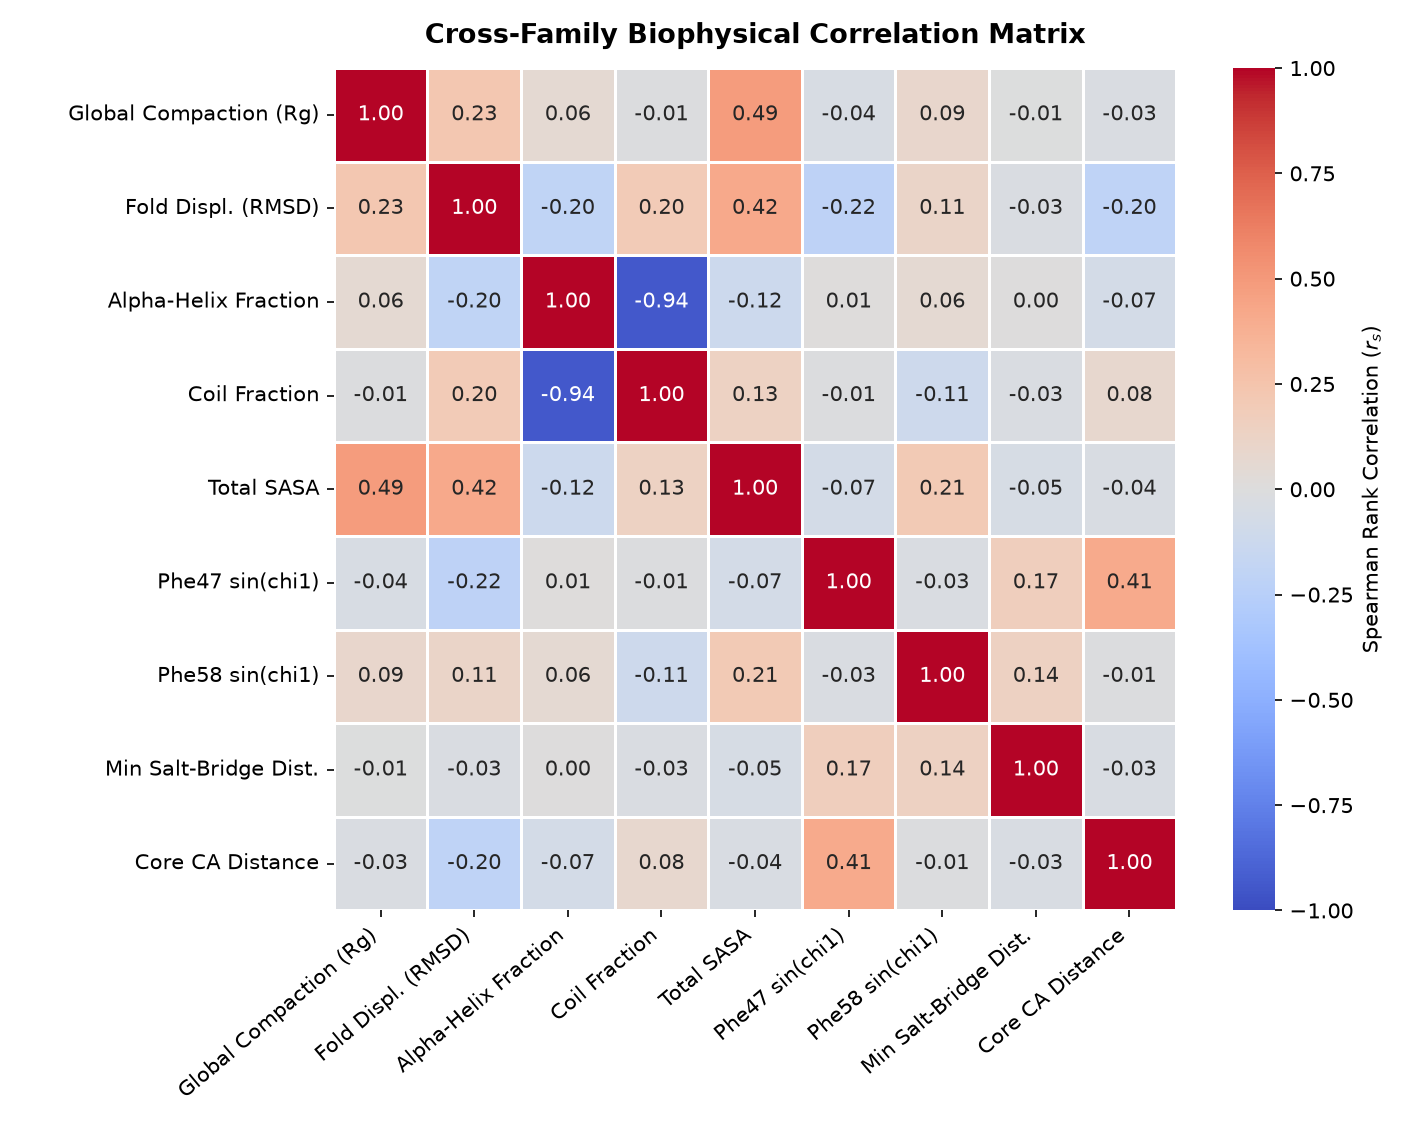

Average Absolute Cross-Correlation per Feature:
  Global Compaction (Rg)      : mean |r_s| = 0.12 (max = 0.49)
  Fold Displ. (RMSD)          : mean |r_s| = 0.20 (max = 0.42)
  Alpha-Helix Fraction        : mean |r_s| = 0.18 (max = 0.94)
  Coil Fraction               : mean |r_s| = 0.19 (max = 0.94)
  Total SASA                  : mean |r_s| = 0.19 (max = 0.49)
  Phe47 sin(chi1)             : mean |r_s| = 0.12 (max = 0.41)
  Phe58 sin(chi1)             : mean |r_s| = 0.10 (max = 0.21)
  Min Salt-Bridge Dist.       : mean |r_s| = 0.06 (max = 0.17)
  Core CA Distance            : mean |r_s| = 0.11 (max = 0.41)


In [6]:
# Select representative descriptors across distinct biophysical families
candidate_keys = [
    ("Global Compaction (Rg)", "GEOM_global_radius_gyration"),
    ("Fold Displ. (RMSD)", "DYN_kabsch_rmsd_to_first_frame"),
    ("Alpha-Helix Fraction", "DSSP_helix_fraction"),
    ("Coil Fraction", "DSSP_coil_fraction"),
    ("Total SASA", "SASA_total"),
    (r"Phe47 sin(chi1)", next((c for c in features.columns if "SIDECHAIN_chi1" in c and "47" in c and "sin" in c), None)),
    (r"Phe58 sin(chi1)", next((c for c in features.columns if "SIDECHAIN_chi1" in c and "58" in c and "sin" in c), None)),
    ("Min Salt-Bridge Dist.", "SALT_BRIDGE_min_distance"),
    ("Core CA Distance", next((c for c in features.columns if "CA_DISTANCE_angstrom" in c and "PHE_47" in c and "PHE_58" in c), None)),
]

selected_labels = []
selected_cols = []
for label, col in candidate_keys:
    if col is not None and col in features.columns and features[col].nunique() > 1:
        selected_labels.append(label)
        selected_cols.append(col)

sub_features = features[selected_cols].copy()
sub_features.columns = selected_labels

# Compute pairwise Spearman rank correlation matrix
corr_matrix = sub_features.corr(method="spearman")

plt.figure(figsize=(9.5, 7.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    center=0.0,
    square=True,
    linewidths=0.6,
    cbar_kws={"label": r"Spearman Rank Correlation ($r_s$)"},
)
plt.title("Cross-Family Biophysical Correlation Matrix", fontsize=13, fontweight="bold", pad=12)
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print average absolute correlation per feature
print("Average Absolute Cross-Correlation per Feature:")
for label in selected_labels:
    other_corrs = corr_matrix[label].drop(label).abs()
    print(f"  {label:28s}: mean |r_s| = {other_corrs.mean():.2f} (max = {other_corrs.max():.2f})")

## 8. Summary and Featurization Guidelines

### Key Takeaways
1. **Beyond Pairwise Contacts**: Multi-family biophysical descriptors capture rich conformational phenomena (DSSP transitions, rotamer flips, solvent expansion, salt bridges) that distance matrices cannot resolve alone.
2. **Continuous Circular Torsions**: Using $[\sin(\theta), \cos(\theta)]$ prevents numerical jump artifacts at the $\pm 180^\circ$ periodicity boundary.
3. **Orthogonality & Low Collinearity**: As demonstrated by the Spearman correlation matrix, secondary structure, sidechain rotamers, and solvent exposure exhibit low cross-correlation ($|r_s| \sim 0.1 - 0.4$), providing truly complementary biophysical signals.
4. **Safety & Zero-Imputation**: When topologies lack specific metadata (e.g., bond topology), MolScope reports explicit applicability status without silent imputation or phantom default parameters.